# Distance Travelled vs Noise Level (from Rollout Datasets)

Calculates integrated distance travelled at each noise level from H5 files produced by
`collect_rollout_dataset` or `collect_rollout_dataset_distill`.
These files contain `prior_logvar_X_qpos` datasets for different fixed log-variance values,
plus `prior_deterministic_qpos` and `prior_predicted_logvar_qpos`.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

In [2]:
# ============ CONFIGURATION ============
# Two H5 files to compare
DATASET_PATH_A = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"  # Update this path
DATASET_PATH_B = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_matchKL_clamp_49.h5"  # Update this path

LABEL_A = "SCAMPER"
LABEL_B = "PULSE"

# Encoder baseline dataset names (set to None to skip)
ENCODER_DATASET_A = "encoder_decoder_qpos"  # SCAMPER encoder-decoder
ENCODER_DATASET_B = "student_encoder_decoder_qpos"  # PULSE student encoder-decoder

# Save path for figures
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
SAVE_NAME = "distance_vs_noise_comparison"

## Load Dataset

In [3]:
def calculate_distance_travelled(qpos: np.ndarray) -> np.ndarray:
    """Calculate total distance travelled for each rollout.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim) - first 2 elements are x, y.

    Returns:
        distances: Shape (num_rollouts,) - total distance per rollout.
    """
    xy = qpos[:, :, :2]
    diffs = np.diff(xy, axis=1)
    step_distances = np.linalg.norm(diffs, axis=2)
    return np.sum(step_distances, axis=1)


def logvar_to_std(logvar: float) -> float:
    """Convert log-variance to standard deviation."""
    return np.exp(0.5 * logvar)


def parse_dataset_name(name: str, logvars: np.ndarray) -> dict:
    """Parse a qpos dataset name into noise level metadata."""
    stem = name.removesuffix("_qpos")

    if stem == "prior_deterministic":
        return {"std": 0.0, "sort_key": 0.0, "label": "deterministic"}
    elif stem == "prior_predicted_logvar":
        return {"std": None, "sort_key": np.inf, "label": "predicted"}
    elif stem.startswith("prior_logvar_"):
        logvar_str = stem.removeprefix("prior_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    else:
        return {"std": None, "sort_key": np.inf, "label": stem}


def load_qpos_datasets(path):
    """Load all qpos datasets (except original) from an H5 file."""
    datasets = {}
    with h5py.File(path, "r") as f:
        logvars = f.attrs["logvars"]
        original_qpos = f["original_qpos"][:] if "original_qpos" in f else None
        for key in f.keys():
            if key.endswith("_qpos") and key != "original_qpos":
                datasets[key] = f[key][:]
    return datasets, logvars, original_qpos


qpos_a, logvars_a, original_qpos = load_qpos_datasets(DATASET_PATH_A)
qpos_b, logvars_b, _ = load_qpos_datasets(DATASET_PATH_B)
print(f"{LABEL_A}: {len(qpos_a)} datasets, logvars={logvars_a}")
print(f"{LABEL_B}: {len(qpos_b)} datasets, logvars={logvars_b}")
if original_qpos is not None:
    print(f"Original qpos: {original_qpos.shape}")

# Compute encoder baseline distances
encoder_dist_a = None
if ENCODER_DATASET_A and ENCODER_DATASET_A in qpos_a:
    encoder_dist_a = calculate_distance_travelled(qpos_a[ENCODER_DATASET_A])
    print(f"\n{LABEL_A} encoder baseline ({ENCODER_DATASET_A}): mean={encoder_dist_a.mean():.2f} +/- {encoder_dist_a.std():.2f}")

encoder_dist_b = None
if ENCODER_DATASET_B and ENCODER_DATASET_B in qpos_b:
    encoder_dist_b = calculate_distance_travelled(qpos_b[ENCODER_DATASET_B])
    print(f"{LABEL_B} encoder baseline ({ENCODER_DATASET_B}): mean={encoder_dist_b.mean():.2f} +/- {encoder_dist_b.std():.2f}")

# Compute original (reference) baseline distance
original_dist = None
if original_qpos is not None:
    original_dist = calculate_distance_travelled(original_qpos)
    print(f"\nOriginal (reference) baseline: mean={original_dist.mean():.2f} +/- {original_dist.std():.2f}")

SCAMPER: 9 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
PULSE: 10 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Original qpos: (842, 250, 74)

SCAMPER encoder baseline (encoder_decoder_qpos): mean=0.54 +/- 0.31
PULSE encoder baseline (student_encoder_decoder_qpos): mean=0.44 +/- 0.32

Original (reference) baseline: mean=0.45 +/- 0.29


## Calculate Distance Travelled

In [4]:
def build_distance_df(qpos_datasets, logvars, method_label):
    """Build a DataFrame of per-clip distances for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        distances = calculate_distance_travelled(qpos)
        for clip_idx, dist in enumerate(distances):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "distance": dist,
                }
            )
    return pd.DataFrame(rows)


df_a = build_distance_df(qpos_a, logvars_a, LABEL_A)
df_b = build_distance_df(qpos_b, logvars_b, LABEL_B)
df = pd.concat([df_a, df_b], ignore_index=True)

print(f"Total rollouts: {len(df)} ({LABEL_A}: {len(df_a)}, {LABEL_B}: {len(df_b)})")
df.head(10)

Total rollouts: 15998 (SCAMPER: 7578, PULSE: 8420)


,method,dataset,std,sort_key,label,clip_idx,distance
0,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,0,0.457967
1,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,1,0.793472
2,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,2,0.343616
3,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,3,0.535121
4,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,4,0.235513
5,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,5,0.083758
6,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,6,0.387563
7,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,7,0.303776
8,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,8,0.710883
9,SCAMPER,encoder_decoder_qpos,NaN,inf,encoder_decoder,9,0.234421


In [5]:
summary = (
    df.groupby(["method", "dataset", "label", "sort_key"])
    .agg(
        distance_mean=("distance", "mean"),
        distance_std=("distance", "std"),
        n_clips=("distance", "count"),
    )
    .reset_index()
    .sort_values(["method", "sort_key"])
)
summary["distance_std"] = summary["distance_std"].fillna(0)
print(summary.to_string(index=False))

 method                      dataset                   label  sort_key  distance_mean  distance_std  n_clips
  PULSE     prior_deterministic_qpos           deterministic  0.000000       0.351725      0.240583      842
  PULSE         prior_logvar_-4_qpos               std=0.135  0.135335       0.365033      0.230597      842
  PULSE         prior_logvar_-3_qpos               std=0.223  0.223130       0.382266      0.221253      842
  PULSE         prior_logvar_-2_qpos               std=0.368  0.367879       0.429943      0.215826      842
  PULSE         prior_logvar_-1_qpos               std=0.607  0.606531       0.538175      0.223108      842
  PULSE       prior_logvar_-0.5_qpos               std=0.779  0.778801       0.618274      0.231161      842
  PULSE          prior_logvar_0_qpos               std=1.000  1.000000       0.753285      0.276878      842
  PULSE  prior_predicted_logvar_qpos               predicted       inf       0.781642      0.256567      842
  PULSE student_enc

## Summary Statistics

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison.[pdf|svg|png]


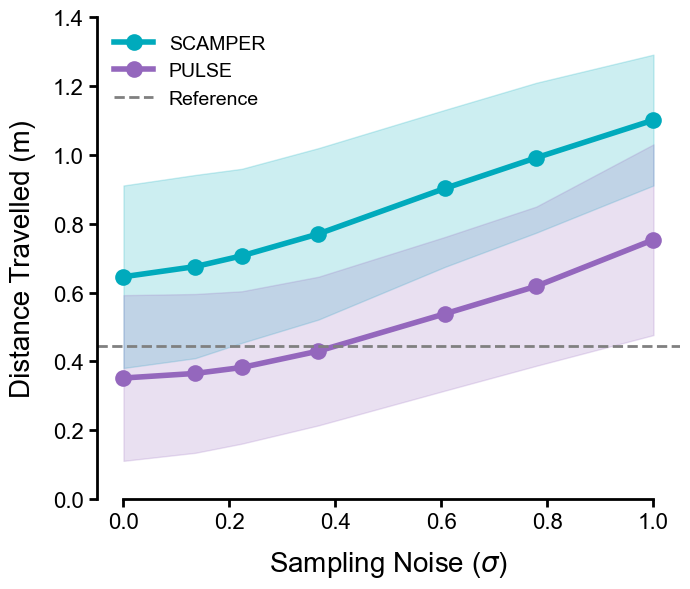

In [10]:
import matplotlib
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill


# Keep only prior_logvar and prior_deterministic datasets (fixed noise levels)
plot_df = df[np.isfinite(df["sort_key"])].copy()
plot_df["noise_std"] = plot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=plot_df[plot_df["method"] == LABEL_A],
    x="noise_std",
    y="distance",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=plot_df[plot_df["method"] == LABEL_B],
    x="noise_std",
    y="distance",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Original (reference) baseline
if original_dist is not None:
    ax.axhline(
        original_dist.mean(),
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Reference",
    )

ax.set_ylim(0, 1.4)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Distance Travelled (m)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

sns.despine(ax=ax)

# Trim spines to tick/ylim range
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(0, 1.4)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / SAVE_NAME}.[pdf|svg|png]")

plt.show()

## Rearing Transition Analysis

Detect rearing events by counting threshold crossings on the root z-position (`qpos[:, 2]`).
Use the cells below to find a rearing clip, tune the threshold, then plot transitions vs noise level.

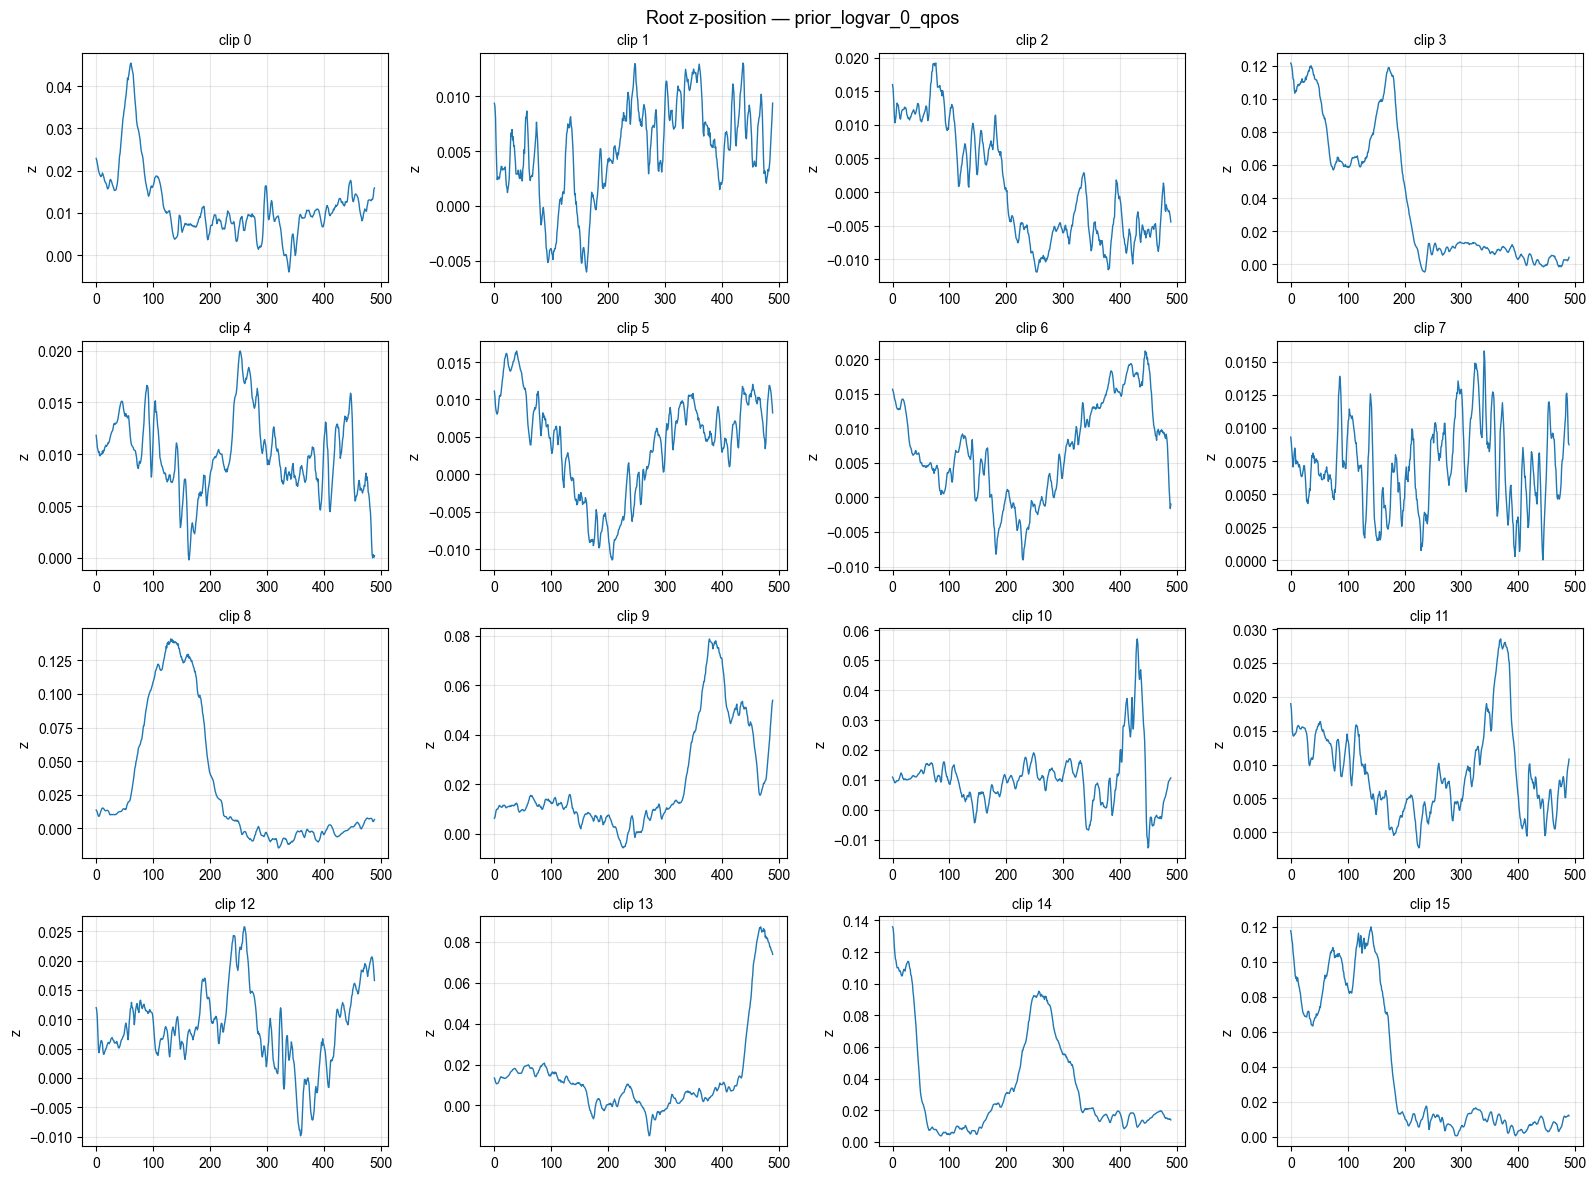

In [11]:
# Render z-position over time for a few clips to find rearing behaviour.
# Pick a dataset and a range of clip indices to inspect.
INSPECT_DATASET = "prior_logvar_0_qpos"  # high noise is more likely to rear
INSPECT_CLIPS = range(0, 16)  # adjust to browse more clips

inspect_qpos = qpos_a[INSPECT_DATASET]  # change to qpos_b to inspect the other file

ncols = 4
nrows = int(np.ceil(len(INSPECT_CLIPS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)

for idx, clip_idx in enumerate(INSPECT_CLIPS):
    ax = axes[idx // ncols][idx % ncols]
    z = inspect_qpos[clip_idx, :, 2]
    ax.plot(z, linewidth=1)
    ax.set_title(f"clip {clip_idx}", fontsize=10)
    ax.set_ylabel("z")
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(len(INSPECT_CLIPS), nrows * ncols):
    axes[idx // ncols][idx % ncols].set_visible(False)

plt.suptitle(f"Root z-position — {INSPECT_DATASET}", fontsize=13)
plt.tight_layout()
plt.show()

In [12]:
import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import mujoco
import mediapy as media
from scamper.environment.rodent import imitation
from scamper.environment import wrappers as vnl_wrappers
from scamper.environment.reference_clips import ReferenceClips
import cv2

# ============ RENDER CONFIGURATION ============
RENDER_CLIP = 8  # <-- set to a clip index that shows rearing
RENDER_DATASET = INSPECT_DATASET
RENDER_QPOS_SOURCE = qpos_a  # change to qpos_b for the other file
REFERENCE_DATA_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5"
CAMERA_NAME = "close_profile-rodent"
RENDER_FPS = 50
RENDER_HEIGHT = 480
RENDER_WIDTH = 640

# Create environment for rendering
reference_clips = ReferenceClips(data_path=REFERENCE_DATA_PATH, n_frames_per_clip=250)
env = vnl_wrappers.FlattenObsWrapper(imitation.Imitation(clips=reference_clips))
mj_model = env.mj_model
mj_data = mujoco.MjData(mj_model)
renderer = mujoco.Renderer(mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

# Render with timestep overlay
qpos_traj = RENDER_QPOS_SOURCE[RENDER_DATASET][RENDER_CLIP]
frames = []

for t, qpos in enumerate(qpos_traj):
    mj_data.qpos[:] = qpos
    mujoco.mj_forward(mj_model, mj_data)
    renderer.update_scene(mj_data, camera=CAMERA_NAME)
    frame = renderer.render().copy()

    # Burn in timestep text

    cv2.putText(
        frame,
        f"t={t}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    frames.append(frame)

renderer.close()

print(f"Rendered clip {RENDER_CLIP} from {RENDER_DATASET}: {len(frames)} frames")
media.show_video(frames, fps=RENDER_FPS)

Rendered clip 8 from prior_logvar_0_qpos: 490 frames


This browser does not support the video tag.


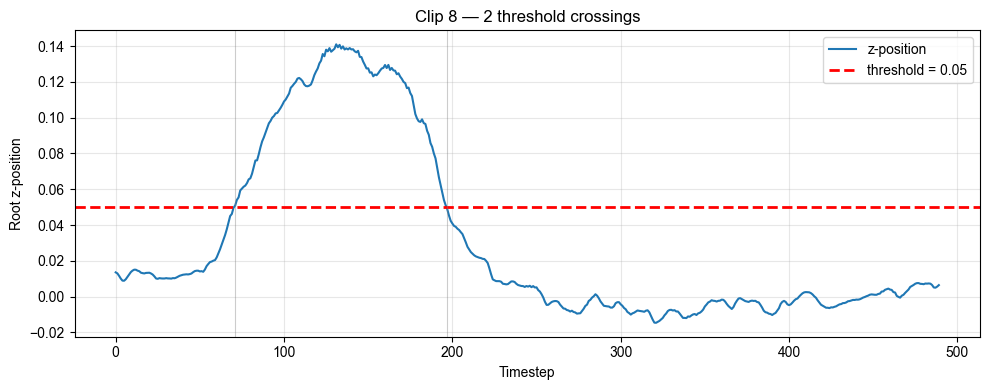

Threshold crossings: 2
Rearing transitions (enter + exit): 2


In [13]:
# Tune the rearing threshold on a specific clip.
# Set REARING_CLIP to a clip index that shows rearing from the grid above.
REARING_CLIP = 8  # <-- update after inspecting the grid
REARING_THRESHOLD = 0.05  # <-- adjust this

z = inspect_qpos[REARING_CLIP, :, 2]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(z, linewidth=1.5, label="z-position")
ax.axhline(REARING_THRESHOLD, color="r", linestyle="--", linewidth=2, label=f"threshold = {REARING_THRESHOLD}")

# Mark crossings
above = (z > REARING_THRESHOLD).astype(int)
crossings = np.where(np.diff(above) != 0)[0] + 1
for c in crossings:
    ax.axvline(c, color="gray", alpha=0.4, linewidth=0.8)

ax.set_xlabel("Timestep")
ax.set_ylabel("Root z-position")
ax.set_title(f"Clip {REARING_CLIP} — {len(crossings)} threshold crossings")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Threshold crossings: {len(crossings)}")
print(f"Rearing transitions (enter + exit): {len(crossings)}")

In [14]:
def count_rearing_transitions(qpos, threshold):
    """Count threshold crossings on z-position for each clip.

    Args:
        qpos: Shape (num_clips, num_steps, qpos_dim).
        threshold: z-position threshold for rearing.

    Returns:
        transitions: Shape (num_clips,) — number of threshold crossings per clip.
    """
    z = qpos[:, :, 2]  # (num_clips, num_steps)
    above = (z > threshold).astype(np.int8)
    crossings = np.abs(np.diff(above, axis=1))  # (num_clips, num_steps-1)
    return crossings.sum(axis=1)


def build_rearing_df(qpos_datasets, logvars, method_label, threshold):
    """Build a DataFrame of per-clip rearing transitions for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        transitions = count_rearing_transitions(qpos, threshold)
        for clip_idx, n in enumerate(transitions):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "transitions": int(n),
                }
            )
    return pd.DataFrame(rows)


rdf_a = build_rearing_df(qpos_a, logvars_a, LABEL_A, REARING_THRESHOLD)
rdf_b = build_rearing_df(qpos_b, logvars_b, LABEL_B, REARING_THRESHOLD)
rdf = pd.concat([rdf_a, rdf_b], ignore_index=True)

# Original (reference) baseline
original_trans = None
if original_qpos is not None:
    original_trans = count_rearing_transitions(original_qpos, REARING_THRESHOLD)
    print(f"Original (reference) rearing transitions: mean={original_trans.mean():.2f} +/- {original_trans.std():.2f}")

print(f"\nTotal rollouts: {len(rdf)}")

Original (reference) rearing transitions: mean=0.65 +/- 0.99

Total rollouts: 15998


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_rearing.[pdf|svg|png]


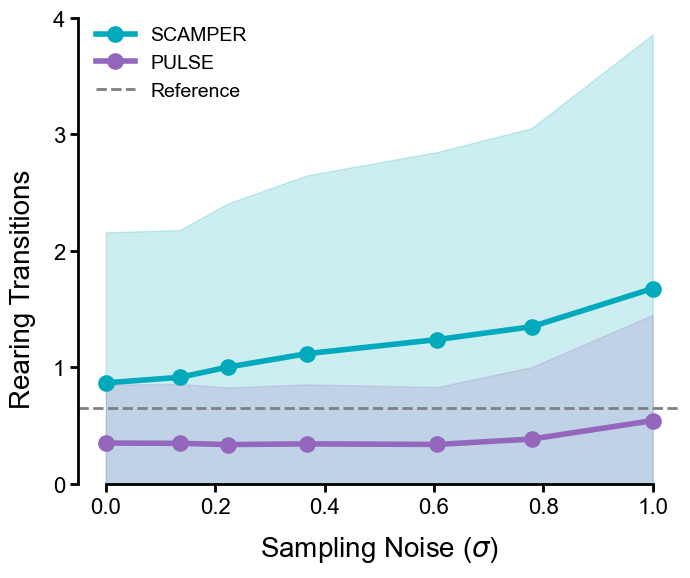

In [15]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill

rplot_df = rdf[np.isfinite(rdf["sort_key"])].copy()
rplot_df["noise_std"] = rplot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=rplot_df[rplot_df["method"] == LABEL_A],
    x="noise_std",
    y="transitions",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=rplot_df[rplot_df["method"] == LABEL_B],
    x="noise_std",
    y="transitions",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Clip error band shading to y >= 0
for child in ax.get_children():
    if isinstance(child, plt.matplotlib.collections.PolyCollection):
        paths = child.get_paths()
        for path in paths:
            path.vertices[:, 1] = np.clip(path.vertices[:, 1], 0, None)

# Original (reference) baseline
if original_trans is not None:
    ax.axhline(
        original_trans.mean(),
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Reference",
    )

ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Rearing Transitions", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

sns.despine(ax=ax)

# Move bottom spine/x-axis up to y=0
ax.spines["bottom"].set_position(("data", 0))

xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(0, yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
rear_save = f"{SAVE_NAME}_rearing"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{rear_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / rear_save}.[pdf|svg|png]")

plt.show()